In [1]:
###
import timeit
import sys
import os
import glob
import warnings
import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random as rd

from astropy.io import fits
from astropy.io import ascii
from astropy.table import Table
from astropy import units as u
from astropy.cosmology import WMAP9 as cosmo
from tqdm import tnrange, tqdm_notebook
from scipy.optimize import curve_fit
from itertools import product

from pkg.colorList import RGB2Hex
from pkg.PyQSOFit.PyQSOFit import QSOFit


##########################################
%matplotlib inline
warnings.filterwarnings("ignore")
##########################################

In [2]:
xl_RGB_List = ('0,0,0','56,72,113','231,189,57','171,79,63','71,133,90')
xm_RGB_List = ('36,50,88','40,114,70','177,1966,77','231,199,54','247,191,99',
               '238,176,175','150,52,96','99,31,102','141,87,41','1,137,157')

xmcl = RGB2Hex(xm_RGB_List)

# Func

In [3]:
def fluxToLuminosity(flux, flux_err, z):
        """flat Universe as h=0.693, OmO=0.286, Tcmb0 = 2.725 K """
        from astropy.cosmology import WMAP9 as cosmo
        DL = cosmo.luminosity_distance(z).cgs.value  ## unit cm
        flux, flux_err = np.array(flux), np.array(flux_err)
        F_a = 4 * np.pi * DL**2                      
        L, L_err = F_a * flux * 1e-17, F_a * flux_err* 1e-17   ## unit erg/s
        return np.array(L), np.array(L_err)

In [4]:
def Seyfert_type(F_4861, F_5007):
    # Winkler 1992 (https://ui.adsabs.harvard.edu/abs/1992MNRAS.257..677W/abstract)
    if F_5007 == 0:
        print("O3 Flux can not be zero!")
        
    ratio = F_4861/F_5007
    if ratio > 5.0:
        return 1.0
    elif 2.0 < ratio <5.0:
        return 1.2
    elif 1/3 < ratio <2.0:
        return 1.5
    elif ratio < 1/3:
        return 1.8

In [5]:
def spectralType(F_na, F_na_err, F_br, F_br_err):
    R = F_na/(F_br) 
    Ft_err = np.sqrt(F_na_err**2 + F_br_err**2)
    R_err = np.sqrt((F_na_err/F_na)**2 + (F_br_err/F_br)**2)
    
    spec_type = 1 + R**(0.4)
    spec_type_err = np.sqrt((0.4*R**(-0.6)*R_err)**2)
    
    return spec_type, spec_type_err 

In [6]:
def virBhMass(L, Lerr, FWHM, FWHM_err, method="Hb", ):
    # mainly from shen et al. 2011a\
    if method == "Hb":
        # VP06
        a, b = 0.910, 0.50    
    if method == "MgII":
        # VO09
        a, b = 0.860, 0.50
    if method == "CIV":
        # VP06
        a, b = 0.660, 0.53
        
    Mvir = a + b*np.log10(L/1e44) + 2*np.log10(FWHM)
    Mvir_err = np.sqrt((Lerr*0.43/np.log(10)/L)**2 + (FWHM_err*2.1/np.log(10)/FWHM)**2)
    
    return Mvir, Mvir_err

In [7]:
def lcontiToLbol(L_conti, L_conti_err, wave='5100', ):
    
    # default in log scale. reference Richards et al. 2006a 
    if wave == "5100":
        f = np.log10(9.26)
    if wave == "3000":
        f = np.log10(5.15)
    if wave == "1350":
        f = np.log10(3.81)

    Lbol = L_conti + f 
    Lbol_err = L_conti_err 
    
    return Lbol, Lbol_err 

In [8]:
def mag2L(mag, mag_err, dist, ins, band, logscale = True):
    
    if ins == 'ZTF':
        if band == 'g':
            lambda_eff = 4722.74 * 10**(-10)
            F_nu0 = 3963.97
        if band == 'r':
            lambda_eff = 6339.61 * 10**(-10)
            F_nu0 = 3042.00
        if band == 'i':
            lambda_eff = 7886.13 * 10**(-10)
            F_nu0 = 2426.09
    if ins == 'WISE':
        if band == 'W1':
            lambda_eff = 33526.00 * 10**(-10)
            F_nu0 = 309.540
        if band == 'W2':
            lambda_eff = 46028.00 * 10**(-10)
            F_nu0 = 171.787
            
    c = 299792458  
    nu = c/lambda_eff 
    
    mag = np.array(mag)
    mag_err = np.array(mag_err)
        
    F_nu = F_nu0 * 10**(-mag/2.5)
    F_nu_err = np.sqrt((np.log(10)*F_nu*mag_err)**2)
    
    nuL = F_nu * 10**(-23) * nu * 4*np.pi*dist**2
    nuL_err = F_nu_err * 10**(-23) * nu * 4*np.pi*dist**2
    
    log_nuL = np.log10(nuL)
    log_nuL_err = np.sqrt((nuL_err/nuL)**2)/np.log(10)

    
    if logscale:
        return np.array(log_nuL), np.array(log_nuL_err)
    else:
        return np.array(nu_L), np.array(nu_L_err)

In [9]:
def reBin(mjd, mag, binSize):
    t_list_bin = np.unique(mjd//binSize)
    t_norm = np.array(mjd//binSize)
    
    t_bin = []
    mag_bin = []
    mag_err_bin = []
    for i in np.arange(len(t_list_bin)):
        ii = t_list_bin[i]
        t_list = []
        mag_list = []
        for j in np.arange(len(t_norm)):
            jj = t_norm[j]
            if jj == ii:
                t_list.append(mjd[j])
                mag_list.append(mag[j])
            else:
                t_list.append(np.nan)
                mag_list.append(np.nan)
        t_bin.append(np.nanmedian(np.array(t_list)))
        mag_bin.append(np.nanmedian(np.array(mag_list)))
        mag_err_bin.append(np.nanstd(np.array(mag_list)))

    t_bin = np.array(t_bin)
    mag_bin = np.array(mag_bin)
    mag_err_bin = np.array(mag_err_bin)
    
    return t_bin, mag_bin, mag_err_bin

In [10]:
def lcNeoWise(lc_file,binSize = 100):
    
    wise_df = pd.read_csv(lc_file)
    wise_sort_df = wise_df.sort_values(by="mjd", ascending=True)
    tMjd = np.array(wise_sort_df["mjd"])
    magW1 = np.array(wise_sort_df["w1mpro"])
    magW1Err = np.array(wise_sort_df["w1sigmpro"])
    magW2 = np.array(wise_sort_df["w2mpro"])
    magW2Err = np.array(wise_sort_df["w2sigmpro"])
    
    tBin, magW1Bin, magW1ErrBin = reBin(tMjd, magW1, binSize)
    tBin, magW2Bin, magW2ErrBin = reBin(tMjd, magW2, binSize)
    
    return tBin, magW1Bin, magW1ErrBin, magW2Bin, magW2ErrBin

In [11]:
def lcZTF(lc_file, ifBin=False, binSize=10):
    
    lc = fits.open(lc_file)
    tMjd = lc[1].data["mjd"]
    mag = lc[1].data["mag"]
    magErr = lc[1].data["magerr"]
    
    if ifBin:
        tBin, magBin, magErrBin = reBin(tMjd, mag, binSize)
        return tBin, magBin, magErrBin
    else:
        return tMjd, mag, magErr

In [12]:
def lcFile(target_name, target_z, lc_data_path, neoWISE_path, ZTF_path, 
           binSizeWISE=100, ifBin=False, binSizeZTF=10, log_scale=True, save_data=False, ):
    ######### load data ########
    
    ####### WISE #########
    neoWISE_lc_file = glob.glob(dataPath+neoWISE_path+"*"+target_name+"*")[0]
    mjd_WISE, mag_W1, mag_err_W1, mag_W2, mag_err_W2 = lcNeoWise(neoWISE_lc_file, binSize = binSizeWISE)
    nuL_W1, nuL_err_W1 = magToLuminosity(mag_W1, mag_err_W1, target_z, ins="WISE", band="W1", log_scale=log_scale)
    nuL_W2, nuL_err_W2 = magToLuminosity(mag_W2, mag_err_W2, target_z, ins="WISE", band="W2", log_scale=log_scale)
    band_W1 = list(len(mjd_WISE)*["W1"])
    band_W2 = list(len(mjd_WISE)*["W2"])
    
    ###### ZTF  ##########
    ZTF_band_list = ["ZTFg","ZTFr","ZTFi"]
    file_list = glob.glob(dataPath+ZTF_path+"*"+target_name+"*")
    band = [i for i,j in product(ZTF_band_list,file_list) if i in j]
    
    if "ZTFg" in band:
        ZTFg_lc_file = [i for i in file_list if "ZTFg" in i][0]
        mjd_ZTFg, mag_ZTFg, mag_err_ZTFg = lcZTF(ZTFg_lc_file, ifBin=ifBin, binSize=binSizeZTF)
        nuL_g, nuL_err_g = magToLuminosity(mag_ZTFg, mag_err_ZTFg, target_z, ins="ZTF", band="g", log_scale=log_scale)
        band_g = list(len(mjd_ZTFg)*["g"])
    else:
        mjd_ZTFg, mag_ZTFg, mag_err_ZTFg, nuL_g, nuL_err_g, band_g = [],[],[],[],[],[]
        
    if "ZTFr" in band:
        ZTFr_lc_file = [i for i in file_list if "ZTFr" in i][0]
        mjd_ZTFr, mag_ZTFr, mag_err_ZTFr = lcZTF(ZTFr_lc_file, ifBin=ifBin, binSize=binSizeZTF)
        nuL_r, nuL_err_r = magToLuminosity(mag_ZTFr, mag_err_ZTFr, target_z, ins="ZTF", band="r", log_scale=log_scale)
        band_r = list(len(mjd_ZTFr)*["r"])
    else:
        mjd_ZTFr, mag_ZTFr, mag_err_ZTFr, nuL_r, nuL_err_r, band_r = [],[],[],[],[],[]
        
    if "ZTFi" in band:
        ZTFi_lc_file = [i for i in file_list if "ZTFi" in i][0]
        mjd_ZTFi, mag_ZTFi, mag_err_ZTFi = lcZTF(ZTFi_lc_file, ifBin=ifBin, binSize=binSizeZTF)
        nuL_i, nuL_err_i = magToLuminosity(mag_ZTFi, mag_err_ZTFi, target_z, ins="ZTF", band="i", log_scale=log_scale)
        band_i = list(len(mjd_ZTFi)*["i"])
    else:
        mjd_ZTFi, mag_ZTFi, mag_err_ZTFi, nuL_i, nuL_err_i, band_i = [],[],[],[],[],[]
      

    data = Table()
    data["MJD"] = list(mjd_WISE)+list(mjd_WISE)+list(mjd_ZTFg)+list(mjd_ZTFr)+list(mjd_ZTFi)
    data["mag"] = list(mag_W1)+list(mag_W2)+list(mag_ZTFg)+list(mag_ZTFr)+list(mag_ZTFi)
    data["magerr"] = list(mag_err_W1)+list(mag_err_W2)+list(mag_err_ZTFg)+list(mag_err_ZTFr)+list(mag_err_ZTFi)
    data["log_nuL"] = list(nuL_W1)+list(nuL_W2)+list(nuL_g)+list(nuL_r)+list(nuL_i)
    data["log_nuLerr"] = list(nuL_err_W1)+list(nuL_err_W2)+list(nuL_err_g)+list(nuL_err_r)+list(nuL_err_i)
    data["band"] = band_W1+band_W2+band_g+band_r+band_i
    
    if save_data:
        ascii.write(data,lc_data_path+target_name+"_lcData.dat",overwrite=True)
        print("Save data completed")
        
    return

In [13]:
def rebin_lc(mjd, mag, magerr, binsize,):
    t_list_bin = np.unique(mjd//binsize)
    t_norm = np.array(mjd//binsize)
    
    mag_new = []
    mag_err_new = []
    
    for idx in np.arange(len(t_list_bin)):
        ii = t_list_bin[idx]
        mag_list = []
        magerr_list = []
        for j in np.arange(len(t_norm)):
            jj = t_norm[j]
            if jj == ii:
                mag_list.append(mag[j])
                magerr_list.append(magerr[j])

        mag_new.append(np.nanmedian(np.array(mag_list)))
        magerr_list = np.array(magerr_list)

        num_photometry = len(mag_list)
        if num_photometry > 1:
            mag_err = np.sqrt((np.nansum(magerr_list**2) + 
                               num_photometry*np.nanstd(np.array(mag_list))**2)/(num_photometry*(num_photometry-1)))
            mag_err_new.append(mag_err)
        else:
            mag_err_new.append(np.nan)

        # mag_err_new.append(np.nanstd(np.array(mag_list)))

    mag_new = np.array(mag_new)
    mag_err_new = np.array(mag_err_new)
    mjd_new = t_list_bin*binsize
    
    return mjd_new, mag_new, mag_err_new

# Results

## light curves 


In [16]:
def rBandLcFile(target_name, PTF_path, ZTF_path, Panstarrs_path, save_path, save_data=True):
    
    ## PTF 
    global ptf_t
    if os.path.exists(PTF_path):
        data_ptf = pd.read_csv(PTF_path)
        ptf_t = np.array(data_ptf["obsmjd"])
        ptf_r_mag = np.array(data_ptf["mag_autocorr"])
        ptf_r_mag_err = np.array(data_ptf["magerr_auto"])
        
    else:
        ptf_t = [0.0]
        ptf_r_mag = [0.0]
        ptf_r_mag_err = [0.0]
        
    ins_ptf = list(len(ptf_t)*["PTF"])
    
    ## Pan_starrs
    if os.path.exists(Panstarrs_path):
        df_Pan = pd.read_csv(Panstarrs_path)
        T_pan  = np.array(df_Pan['obsTime'])
        F_pan  = np.array(df_Pan['psfFlux'])
        F_panerr = np.array(df_Pan['psfFluxErr'])
        Mag_pan = -2.5*np.log10(F_pan/3631)
        Mag_pan_err = np.sqrt(((-2.5/F_pan/np.log(10))*F_panerr)**2)
        
        ins_pan = list(len(T_pan)*["Pan-STARRS"])
    
    ## ZTF
    if os.path.exists(ZTF_path):
        lc = fits.open(ZTF_path)
        tMjd = lc[1].data["mjd"]
        mag = lc[1].data["mag"]
        magErr = lc[1].data["magerr"]
        
        ins_ztf = list(len(tMjd)*["ZTF"])
        
    
    data = Table()
    data["MJD"] = list(ptf_t)+list(T_pan)+list(tMjd)
    data["mag"] = list(ptf_r_mag)+list(Mag_pan)+list(mag)
    data["magerr"] = list(ptf_r_mag_err)+list(Mag_pan_err)+list(magErr)
    data["inst"] = ins_ptf+ins_pan+ins_ztf
    
    if save_data:
        ascii.write(data,save_path,overwrite=True)
        print("Save data completed")
        
    return

In [17]:
tar_info = ascii.read('data/target_info.dat')

In [20]:
names = list(tar_info['Object'])
del names[6]

In [ ]:
for target_name in names:
    
    PTF_path = 'data/lc/PTF/SDSS_'+target_name+'_PTF_r.csv'
    ZTF_path = 'data/lc/ZTF/SDSS_'+target_name+'_ZTFr.fits'
    Panstarrs_path = 'data/lc/Pan_starrs/SDSS_'+target_name+'_Panstarrs_new.csv'
    save_path = 'data/lc/r_band/'+target_name+'_rband_lc.dat'
    save_data = True
    
    df_lc = rBandLcFile(target_name, PTF_path, ZTF_path, Panstarrs_path, 
                    save_path, save_data=save_data)

Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed


In [25]:
target_name = 'J1603'
PTF_path = 'data/lc/PTF/SDSS_'+target_name+'_PTF_r.csv'
ZTF_path = 'data/lc/ZTF/SDSS_'+target_name+'_ZTFr.fits'
Panstarrs_path = 'data/lc/Pan_starrs/SDSS_'+target_name+'_Panstarrs_new.csv'
save_path = 'data/lc/r_band/'+target_name+'_rband_lc.dat'
save_data = True

In [26]:
df_lc = rBandLcFile(target_name, PTF_path, ZTF_path, Panstarrs_path, 
                    save_path, save_data=save_data)

Save data completed


In [77]:
## WISE light curve, Vega to AB: W1+2.699, W2+3.339
data_WISE = pd.read_csv("data/lc/neoWISE/neoWISESDSSJ1427.csv")
glob.glob('data/lc/neoWISE/*' + tar_name[0] +'*.csv')[0]

'data/lc/neoWISE/neoWISESDSSJ1617.csv'

In [ ]:
WISE_t = np.array(data_WISE["mjd"])
W1_mag = np.array(data_WISE["w1mpro"])
W1_mag_err = np.array(data_WISE["w1sigmpro"])
W2_mag = np.array(data_WISE["w2mpro"])
W2_mag_err = np.array(data_WISE["w2sigmpro"])

W1_mjd_bin, W1_mag_bin, W1_mag_err_bin = rebin_lc(WISE_t, W1_mag, W1_mag_err, 40)
W2_mjd_bin, W2_mag_bin, W2_mag_err_bin = rebin_lc(WISE_t, W2_mag, W2_mag_err, 40)

In [75]:
tar_name[0]

'J1617'

# figure

## All light curves 

In [43]:
tar_name = list(tar_info['Object'])
del tar_name[2]

In [44]:
## SDSS photometry 
SDSS_file = ascii.read('data/target_info_SDSS_photometry.dat')
SDSS_mjd = SDSS_file['SDSS_MJD']
SDSS_mag = SDSS_file['SDSS_rmag']
SDSS_magerr = SDSS_file['SDSS_rmagerr']

In [45]:
inst_l = ['PTF', 'Pan-STARRS', 'ZTF']
markers = ['v', 's', 'o']
labels = ["r [PTF]", "r [Pan-STARRS]", "r [ZTF]"]

In [46]:
## SDSS 
sdss_mjd = []
for i in range(len(tar_name)):
    path = glob.glob("data/SDSS/*" + tar_name[i] +"*.fits")[0]
    data = fits.open(path)
    if 'J1452' in path:
        mjd = 52758
    else:   
        mjd = data[0].header['mjd']  # SDSS MJD
    sdss_mjd.append(mjd)

In [47]:
## GTC
gtc_mjd = []
for i in range(len(tar_name)):
    path = glob.glob("data/GTC-OSIRIS/Sci_spec/combined_grism/*" + tar_name[i] +"*.fits")[0]
    data = fits.open(path)
    mjd  = int(data[0].header['mjd'])
    gtc_mjd.append(mjd)

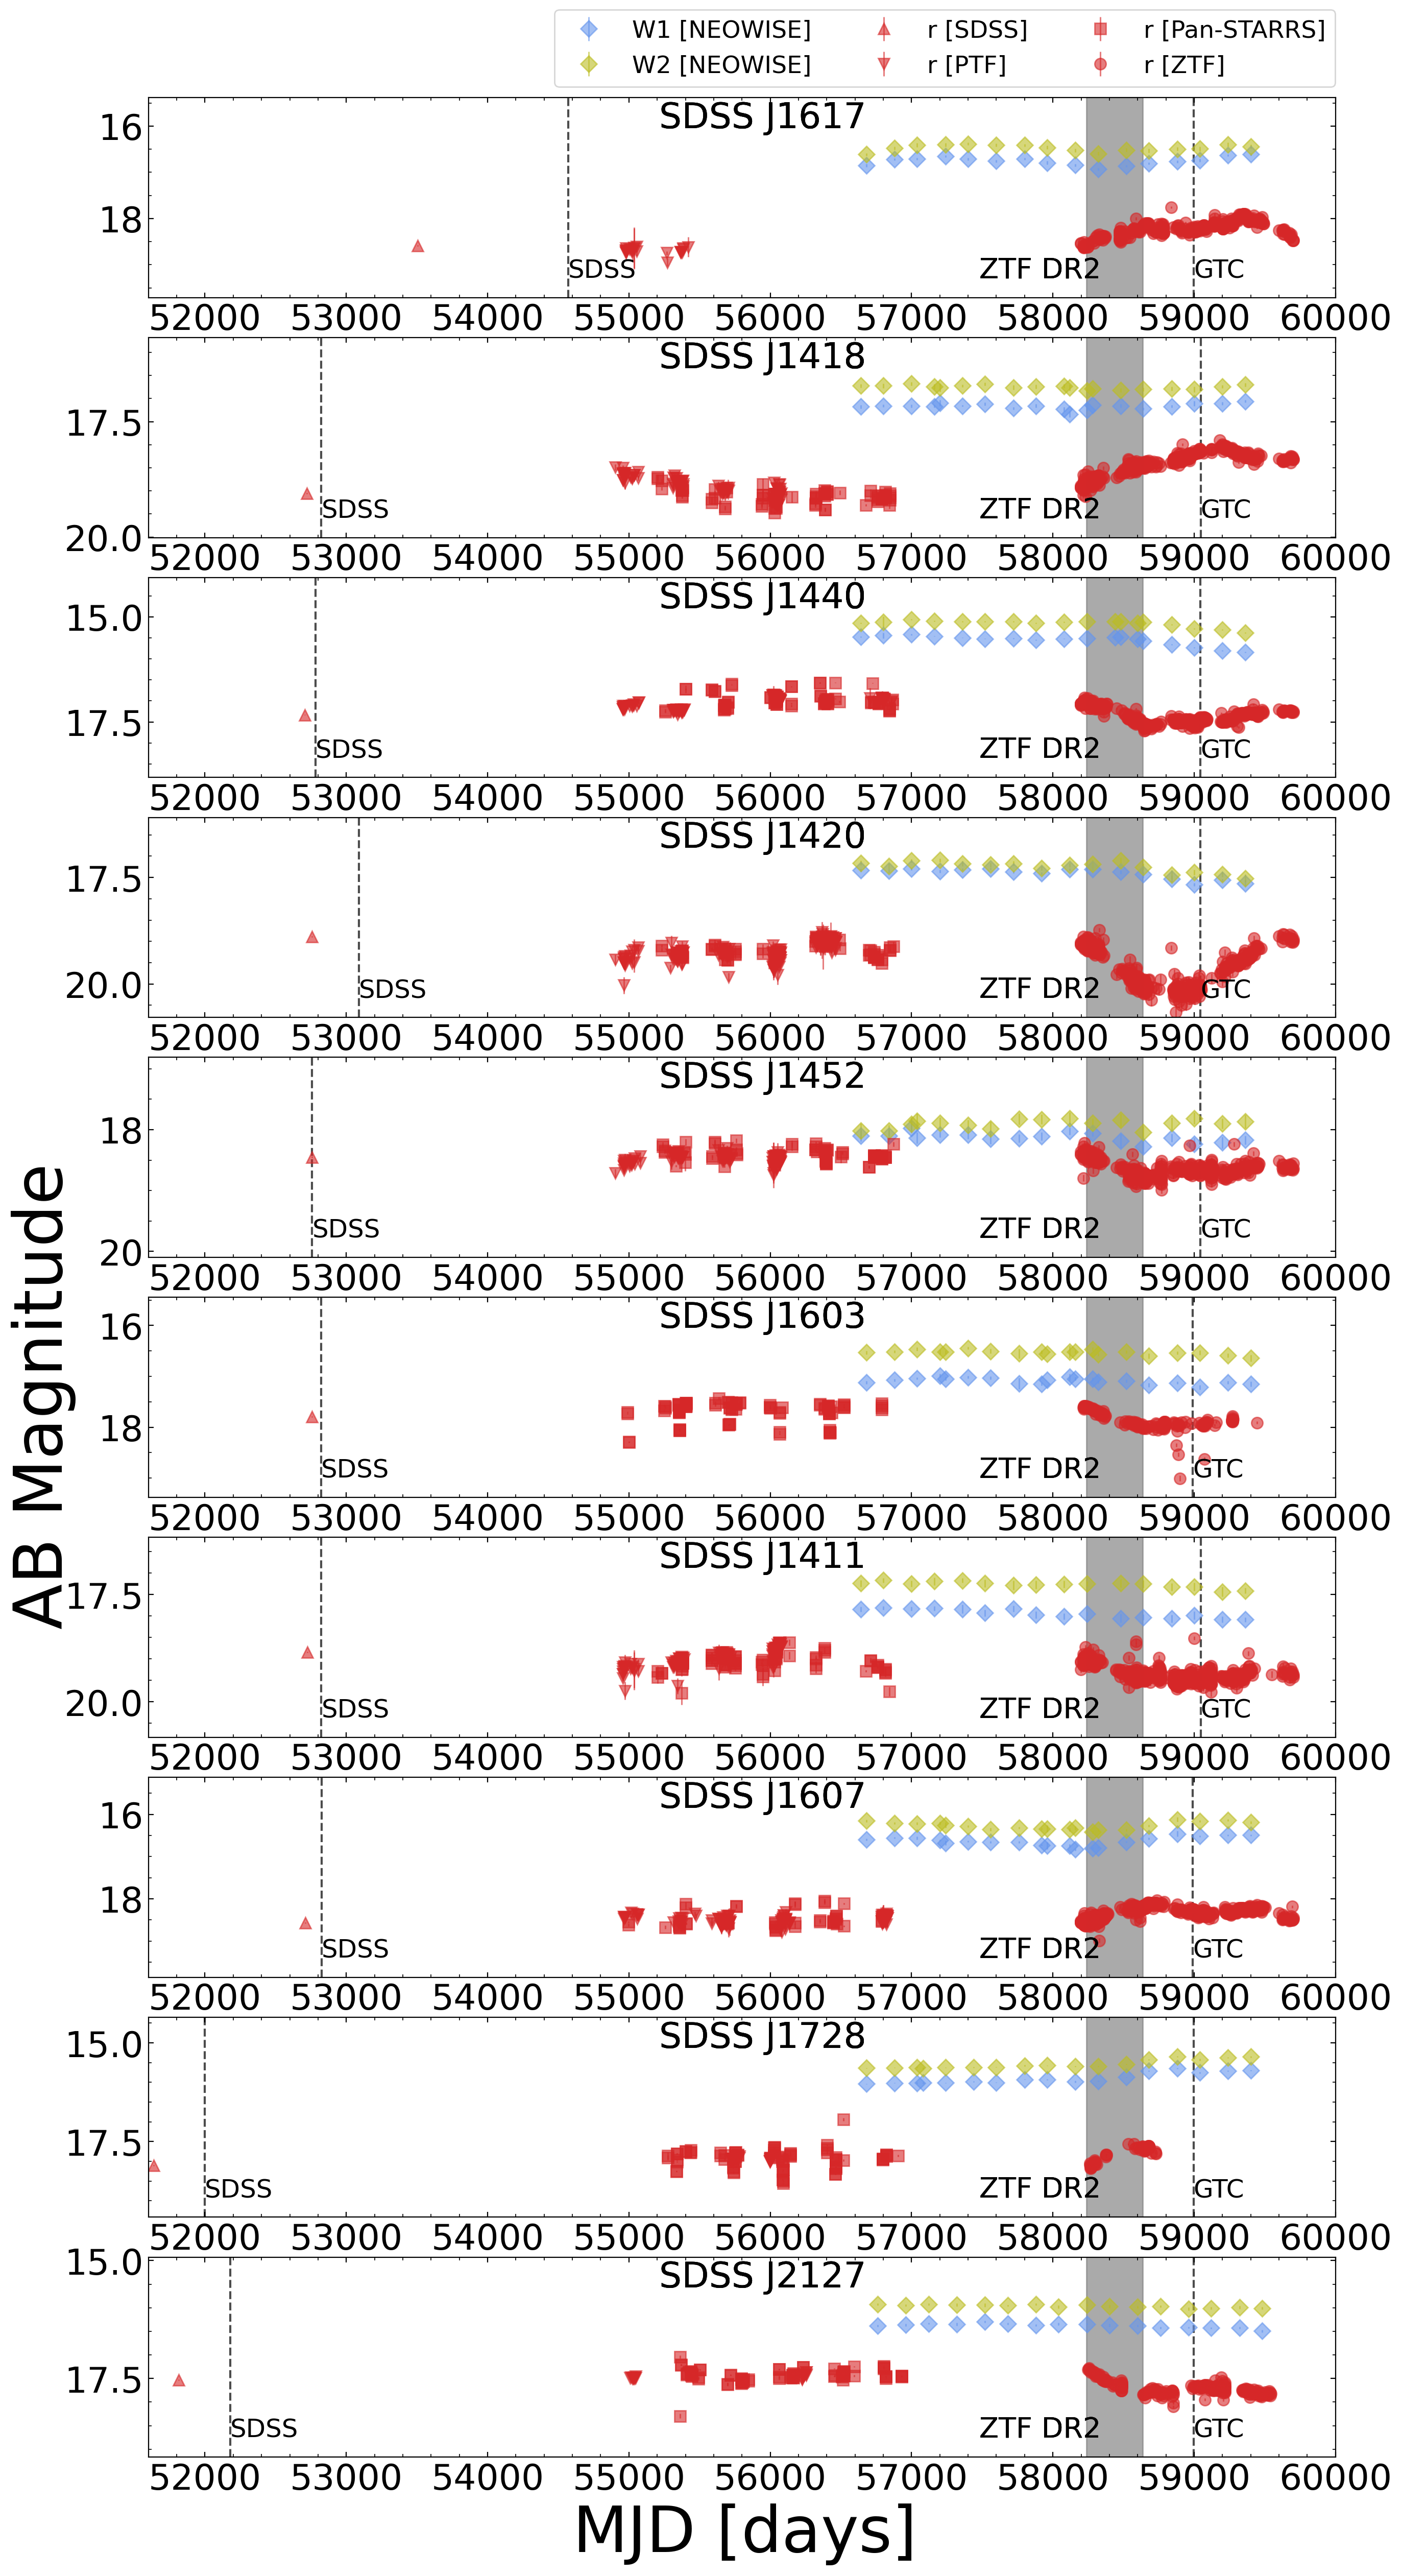

In [115]:
left_tar = tar_name
left_sdss_mjd = sdss_mjd
left_gtc_mjd  = gtc_mjd
left_SDSS_mjd = SDSS_mjd
left_SDSS_mag = SDSS_mag
left_SDSS_mag_err = SDSS_magerr


plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 25
plt.rcParams["ytick.labelsize"] = 25

nrows = len(left_tar)
fig, ax = plt.subplots(nrows=nrows, ncols=1, figsize=(15,nrows*3), squeeze=False, dpi=200) 
ax[-1][0].set_xlabel(r"${\rm MJD\ [days]}$", fontsize=45)

itr = 0
for j in range(nrows):
    
    obj = left_tar[j]
    df_lc = ascii.read('data/lc/r_band/'+obj+'_rband_lc.dat')
    MJD = df_lc['MJD']
    mag = df_lc['mag']
    magerr = df_lc['magerr']
    inst = df_lc['inst']
    
    mag_med = np.nanmedian(mag)

    ## wise lc 
    data_WISE = pd.read_csv(glob.glob('data/lc/neoWISE/*' + tar_name[j] +'*.csv')[0])
    
    WISE_t = np.array(data_WISE["mjd"])
    W1_mag = np.array(data_WISE["w1mpro"])
    W1_mag_err = np.array(data_WISE["w1sigmpro"])
    W2_mag = np.array(data_WISE["w2mpro"])
    W2_mag_err = np.array(data_WISE["w2sigmpro"])
    
    W1_mjd_bin, W1_mag_bin, W1_mag_err_bin = rebin_lc(WISE_t, W1_mag, W1_mag_err, 40)
    W2_mjd_bin, W2_mag_bin, W2_mag_err_bin = rebin_lc(WISE_t, W2_mag, W2_mag_err, 40)

    min_mag = np.nanmin(W2_mag_bin+3.339)
    ax[j][0].set_ylim(mag_med+1.5, min_mag-1)
    ax[j][0].set_xlim(51600, 60000)

    ax[j][0].errorbar(W1_mjd_bin, W1_mag_bin+2.699, yerr = W1_mag_err_bin, linestyle = 'None', 
               color = "cornflowerblue", marker = 'D', ms=8, elinewidth=1.1, alpha = 0.6, label = "W1 [NEOWISE]")

    ax[j][0].errorbar(W2_mjd_bin, W2_mag_bin+3.339, yerr = W2_mag_err_bin, linestyle = 'None', 
               color = "C8", marker = 'D', ms=8, elinewidth=1.1, alpha = 0.6, label = "W2 [NEOWISE]")

    ax[5][0].set_ylabel(r"${\rm AB\ Magnitude }$", fontsize=47, labelpad=15)
    
    _sdss_mjd = left_SDSS_mjd[j]
    _sdss_mag = left_SDSS_mag[j]
    _sdss_magerr = left_SDSS_mag_err[j]
    
    ax[j][0].errorbar(_sdss_mjd, _sdss_mag, yerr = _sdss_magerr, 
                linestyle = 'None', color = "C3", marker = '^', 
                ms=8, elinewidth=1.1, alpha = 0.6, label = "r [SDSS]")
    
    ax[j][0].axvline(x = left_sdss_mjd[j], color = 'k',linestyle="--", alpha=0.7)
    ax[j][0].text((left_sdss_mjd[j]-51600)/(60000-51600),0.1,'SDSS',transform=ax[j][0].transAxes,fontdict={'size': '18', 'color': 'black'})
    ax[j][0].axvline(x = left_gtc_mjd[j], color = 'k',linestyle="--", alpha=0.7)
    ax[j][0].text((left_gtc_mjd[j]-51600) /(60000-51600),0.1,'GTC',transform=ax[j][0].transAxes,fontdict={'size': '18', 'color': 'black'})

    for i in range(len(inst_l)):
        _mjd = MJD[inst==inst_l[i]]
        _mag = mag[inst==inst_l[i]]
        _magerr = magerr[inst==inst_l[i]]
        
        ax[j][0].errorbar(_mjd, _mag, yerr=_magerr,
                    linestyle = 'None', color = "C3", marker = markers[i], 
                    ms=8, elinewidth=1.1, alpha = 0.6, label = labels[i])
        
        ax[j][0].text(0.43,0.85,'SDSS '+obj,transform=ax[j][0].transAxes,fontdict={'size': '25', 'color': 'black'})
        y_t = np.arange(10,25,0.1)
        ax[j][0].fill_betweenx(y_t,np.full_like(y_t,58239),np.full_like(y_t,58635),color='grey', alpha=0.3)
        ax[j][0].text(0.70,0.1,'ZTF DR2',transform=ax[j][0].transAxes,fontdict={'size': '20', 'color': 'black'})
        
    ax[0][0].legend(fontsize=17, ncols=3, bbox_to_anchor=(1.01, 1.5), loc = 'upper right')
    
    
plt.savefig('image/All_lightCurve.pdf',dpi=600,bbox_inches='tight')

In [228]:
rise_subsample = np.array(['J1617', 'J1418', 'J1607', 'J1728', 'J1427'])

dmag = []
dmag_err = []
for i in range(len(rise_subsample)):
    df_lc = ascii.read('data/lc/r_band/'+rise_subsample[i]+'_rband_lc.dat')
    MJD = df_lc['MJD']
    mag = df_lc['mag']
    magerr = df_lc['magerr']

    ZTFDR2_mask = (MJD > 58239) & (MJD < 58635)
    ZTFDR2_mag = mag[ZTFDR2_mask]
    ZTFDR2_magerr = magerr[ZTFDR2_mask]
    max_id = np.where(ZTFDR2_mag==np.nanmax(ZTFDR2_mag))
    min_id = np.where(ZTFDR2_mag==np.nanmin(ZTFDR2_mag))
    dmag_j = np.nanmax(ZTFDR2_mag) - np.nanmin(ZTFDR2_mag)
    dmag_err_j = np.sqrt(ZTFDR2_magerr[max_id]**2 + ZTFDR2_magerr[min_id]**2)
    dmag.append(dmag_j)
    dmag_err.append(dmag_err_j[0])

dmag, dmag_err = np.array(dmag), np.array(dmag_err)

In [229]:
dmag, dmag_err

(array([0.61461067, 0.6769619 , 0.86376381, 0.61981201, 1.52123642]),
 array([0.05249049, 0.06499646, 0.05727123, 0.03638179, 0.09206916]))

In [238]:
np.sqrt(np.sum(dmag_err**2))/5

0.028326770722198004

In [244]:
np.nanmean(dmag[:-1])

0.6937870979309082

## comparison with SDSS QSOs


In [152]:
import seaborn as sns
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KernelDensity

In [175]:
shen_df = fits.open('data/Shen2011/J_ApJS_194_45_catalog.dat.gz.fits')
shen_data = shen_df[1].data
shen_Mbh = shen_data['logBH']
shen_Mbh_err = shen_data['e_logBH']
shen_Edd = shen_data['logEdd']
BHerr_mask = np.where(shen_Mbh_err > 0)

shen_Hab = shen_data['logLBHa']
shen_Hbb = shen_data['logLBHb']
BD_mask = (shen_Hab > 0) & (shen_Hbb > 0)
shen_Bdb = shen_Hab[BD_mask] - shen_Hbb[BD_mask]

In [195]:
Mbh_ = np.array([7.96, 9.42, 8.05, 8.25, 9.14, 9.34, 9.21, 9.49, 8.19, 7.83, 9.36])
Mbh_err_ = np.array([0.13, 0.19, 0.22, 0.11, 0.17, 0.08, 0.14, 0.06, 0.36, 0.09, 0.15])

SDSS_Edd = np.array([-1.13589115, -1.5097973 , -0.97314382, -0.97344682, -1.29747689,
                     -0.15838426, -0.46751556, -1.45417024, -0.58806434, -0.84517498,
                     -1.06922743])
SDSS_Edd_err = np.array([0.12891929, 0.19002106, 0.21608778, 0.11174868, 0.16709858,
                         0.07878754, 0.14439156, 0.06321056, 0.36400786, 0.09267494,
                         0.14640384])
GTC_Edd = np.array([-0.94357288, -1.30527253, -1.13670748, -1.1162731 , -2.41671327,
                    -0.58305858, -0.70639969, -1.90792933, -0.57744337, -1.00815282,
                    -1.26878346])
GTC_Edd_err = np.array([0.12706276, 0.1899638 , 0.21601181, 0.11161317, 0.16844785,
                        0.07883143, 0.14440173, 0.06321361, 0.36396299, 0.09266294,
                        0.14628475])

SDSS_BD = np.array([3.24555687, 3.62938434, 2.9174333 , 2.66613495])
SDSS_BD_err = np.array([0.07442351, 0.26120164, 0.15307959, 0.1123209 ])
GTC_BD = np.array([3.31658024, 5.44755348, 5.06968479, 6.05484835])
GTC_BD_err = np.array([0.16591272, 0.29634804, 0.11974942, 0.15121599])

SDSS_logBD = np.log10(SDSS_BD)

GTC_logBD = np.log10(GTC_BD)

### BH mass & Eddington ratio

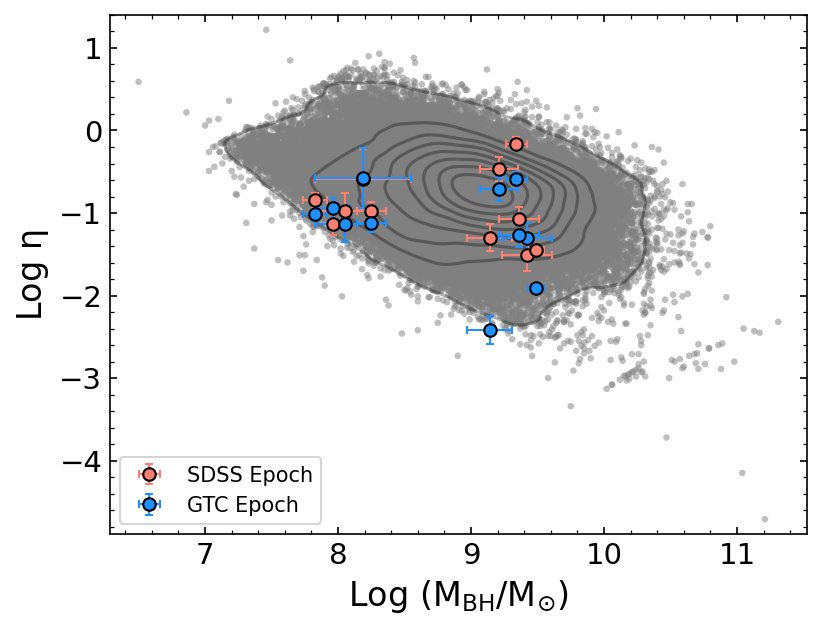

In [241]:
fig = plt.figure(figsize = (6,4.5), dpi = 150)
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm Log\ (M_{BH}/M_{\odot})}$", fontsize=16)
ax.set_ylabel(r"${\rm Log\ \eta }$", fontsize=16)

ax.scatter(shen_Mbh[BHerr_mask], shen_Edd[BHerr_mask], marker='o', 
           s=10, alpha=0.5, color='grey', edgecolor='None')
# ax.errorbar(x = shen_Mbh[BHerr_mask], xerr = shen_Mbh_err[BHerr_mask], y = shen_Edd[BHerr_mask], 
#             linestyle = 'None', marker="o", elinewidth=1,ms=6,capsize=2,)

# rx, ry = shen_Mbh[BHerr_mask], shen_Edd[BHerr_mask]
# xy = np.vstack([rx, ry])
# kde = KernelDensity(kernel='cosine', bandwidth=1).fit(xy.T)

# z = np.exp(kde.score_samples(xy.T))
# idx = z.argsort()
# x, y, z = rx[idx], ry[idx], z[idx]
sns.kdeplot(x=x, y=y, color='k', levels=9, thresh=0.01, alpha=0.3)

ax.errorbar(x = Mbh_, xerr = Mbh_err_, y = SDSS_Edd, yerr = SDSS_Edd_err, 
            linestyle = 'None', marker="o", elinewidth=1,ms=6,capsize=2,
            color='salmon',markeredgecolor='k',label='SDSS Epoch')

ax.errorbar(x = Mbh_, xerr = Mbh_err_, y = GTC_Edd, yerr = GTC_Edd_err, 
            linestyle = 'None', marker="o", elinewidth=1,ms=6,capsize=2,
            color='dodgerblue',markeredgecolor='k', label='GTC Epoch')

ax.legend(loc='lower left', )

plt.savefig('image/BHmass_Eddington_wholeSDSS.pdf', dpi=600, bbox_inches='tight')

### Balmer Decrement

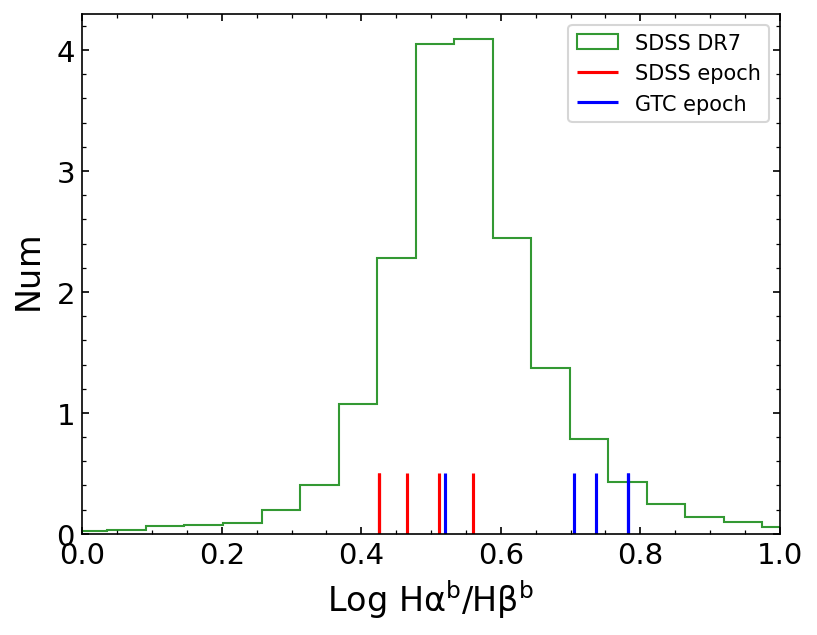

In [242]:
## Balmer Decrement
fig = plt.figure(figsize = (6,4.5), dpi = 150)
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm Log\ H\alpha^b / H\beta^b }$", fontsize=16)
ax.set_ylabel(r"${\rm Num }$", fontsize=16)
ax.set_xlim(0.0, 1.0)

ax.hist(shen_Bdb, bins=50, density=True, histtype='step', color='g', alpha=0.8, label = 'SDSS DR7' )

for i in range(len(SDSS_logBD)):
    ax.vlines(SDSS_logBD[i], 0, 0.5, color='red')
    ax.vlines(GTC_logBD[i], 0, 0.5, color='blue')

ax.vlines(SDSS_logBD[i], 0, 0.5, color='red', label='SDSS epoch')
ax.vlines(GTC_logBD[i], 0, 0.5, color='b', label='GTC epoch')
ax.legend()

plt.savefig('image/BD_wholeSDSS.pdf', dpi=600, bbox_inches='tight')